In [1]:
# Since typing pandas or numpy every single time is too long and tedious, we assign them shorter nicknames like pd and np.
# You can technically use any name, such as a wolverine instead of pd and np, but pd and np are the standard conventions used by data scientists.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
# Suppress Pandas SettingWithCopyWarning
pd.options.mode.chained_assignment = None

In [2]:
df2018 = pd.read_csv('germany2018.csv')
df2019 = pd.read_csv('germany2019.csv')
df2020 = pd.read_csv('germany2020.csv')
df2021 = pd.read_csv('germany2021.csv')
df2022 = pd.read_csv('germany2022.csv')
df2023 = pd.read_csv('germany2023.csv')
df2024 = pd.read_csv('germany2024.csv')
df2025 = pd.read_csv('germany2025.csv')
dfWC2026 = pd.read_csv('germany2026WC.csv')

In [3]:
df2018.columns, df2019.columns, df2020.columns, df2021.columns, df2022.columns, df2023.columns, df2024.columns, df2025.columns

(Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        'Opponent', 'Poss', 'Attendance', 'Captain', 'Formation',
        'Opp Formation', 'Referee', 'Match Report', 'Notes'],
       dtype='str'),
 Index(['Date', 'Time', 'Comp', 'Round', 'Day', 'Venue', 'Result', 'GF', 'GA',
        '

In [4]:
df2021.dtypes

Date                 str
Time                 str
Comp                 str
Round                str
Day                  str
Venue                str
Result               str
GF                 int64
GA                 int64
Opponent             str
Poss             float64
Attendance       float64
Captain              str
Formation            str
Opp Formation        str
Referee              str
Match Report         str
Notes            float64
dtype: object

In [5]:
columns_to_remove = [
    'Day', 
    'Attendance',
    'Formation',
    'Opp Formation',
    'Match Report',
    'Notes',
    'Referee'
]
df2018.drop(columns_to_remove, axis=1, inplace=True)
df2019.drop(columns_to_remove, axis=1, inplace=True)
df2020.drop(columns_to_remove, axis=1, inplace=True)
df2021.drop(columns_to_remove, axis=1, inplace=True)
df2022.drop(columns_to_remove, axis=1, inplace=True)
df2023.drop(columns_to_remove, axis=1, inplace=True)
df2024.drop(columns_to_remove, axis=1, inplace=True)
df2025.drop(columns_to_remove, axis=1, inplace=True)

In [6]:
df2020.columns

Index(['Date', 'Time', 'Comp', 'Round', 'Venue', 'Result', 'GF', 'GA',
       'Opponent', 'Poss', 'Captain'],
      dtype='str')

In [7]:
df = pd.concat([df2018, df2019, df2020, df2021, df2022, df2023, df2024, df2025], ignore_index=True)
df

,Date,Time,Comp,Round,Venue,Result,GF,GA,Opponent,Poss,Captain
0,2016-09-04,20:45 (14:45),WCQ,First round,Away,W,3.0,0.0,no Norway,NaN,Manuel Neuer
1,2016-10-08,20:45 (14:45),WCQ,First round,Home,W,3.0,0.0,cz Czechia,NaN,Manuel Neuer
2,2016-10-11,20:45 (14:45),WCQ,First round,Home,W,2.0,0.0,nir Northern Ireland,NaN,Manuel Neuer
3,2016-11-11,20:45 (14:45),WCQ,First round,Away,W,8.0,0.0,sm San Marino,NaN,Sami Khedira
4,2017-03-26,20:00 (12:00),WCQ,First round,Away,W,4.0,1.0,az Azerbaijan,NaN,Sami Khedira
...,...,...,...,...,...,...,...,...,...,...,...
73,2024-07-05,18:00 (12:00),UEFA Euro,Quarter-finals,Neutral,L,1.0,2.0,es Spain,52.0,İlkay Gündoğan
74,2025-03-20,20:45 (15:45),UEFA Nations League,Quarter-finals,Away,W,2.0,1.0,it Italy,59.0,Joshua Kimmich
75,2025-03-23,20:45 (15:45),UEFA Nations League,Quarter-finals,Home,D,3.0,3.0,it Italy,57.0,Joshua Kimmich
76,2025-06-04,21:10 (15:10),UEFA Nations League,Semi-finals,Neutral,L,1.0,2.0,pt Portugal,55.0,Joshua Kimmich


In [ ]:
df['Date'] = pd.to_datetime(df['Date'], yearfirst=True, errors='coerce')


Date        datetime64[us]
Time                   str
Comp                   str
Round                  str
Venue                  str
Result                 str
GF                 float64
GA                 float64
Opponent               str
Poss               float64
Captain                str
dtype: object

In [9]:
df.isna().sum()
df.loc[[df['Time'].isna().idxmax()]]
df.drop(53, inplace=True)


(array([10.,  0., 15.,  0., 24.,  0., 11.,  0.,  7.,  0.,  0.,  2.,  0.,
         3.,  0.,  2.,  0.,  2.,  0.,  1.]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <BarContainer object of 20 artists>)

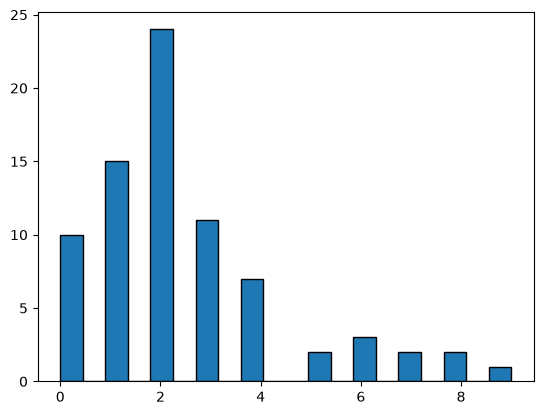

In [10]:
plt.hist(df['GF'], bins = 20, edgecolor = 'black')

(array([ 1.,  6.,  0., 11.,  0., 13., 13.,  0., 13.,  0.,  7.,  5.,  0.,
         1.,  0.,  3.,  1.,  0.,  2.,  1.]),
 array([-3. , -2.4, -1.8, -1.2, -0.6,  0. ,  0.6,  1.2,  1.8,  2.4,  3. ,
         3.6,  4.2,  4.8,  5.4,  6. ,  6.6,  7.2,  7.8,  8.4,  9. ]),
 <BarContainer object of 20 artists>)

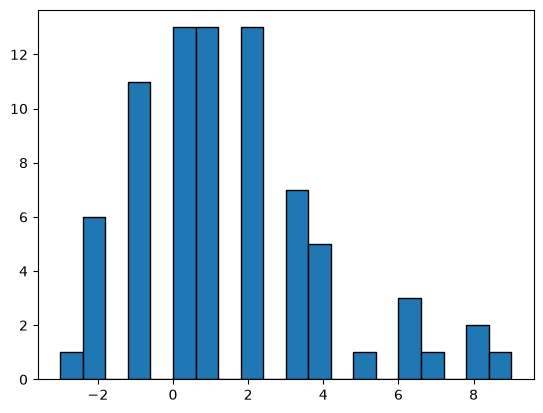

In [11]:
plt.hist(df['GF'] - df['GA'], bins = 20, edgecolor = 'black')

In [12]:
corrs = df.corr(numeric_only=True)
corrs

,GF,GA,Poss
GF,1.000000,-0.298199,0.431318
GA,-0.298199,1.000000,-0.538332
Poss,0.431318,-0.538332,1.000000


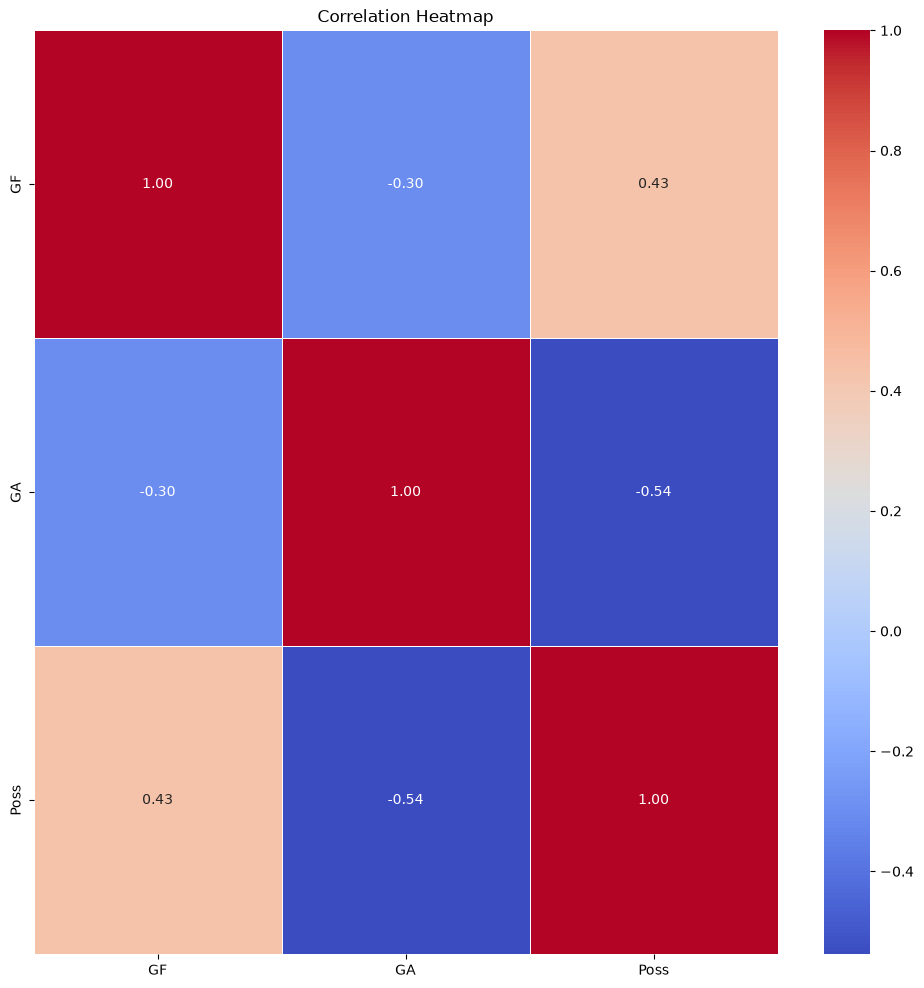

In [13]:
plt.figure(figsize=(12, 12)) # Adjust figure size as needed
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()